<a href="https://colab.research.google.com/github/matiashhidalgo/metodos_multivariados/blob/main/MANOVA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Análisis Multivariado de Varianza
## Ejemplo: Comparación de Métodos de Enseñanza
## Actividad MANOVA
### Dr. Hugo García Tecocoatzi

In [ ]:
# Bibliotecas necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from scipy import stats
from sklearn.datasets import load_iris, load_wine, load_diabetes # Necesaria para la actividad
from scipy.stats import f_oneway
from statsmodels.multivariate.manova import MANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd

import statsmodels.api as sm
from statsmodels.formula.api import ols

%matplotlib inline

In [ ]:
# Generar datos sintéticos para el ejemplo
np.random.seed(42)

# Parámetros
n_por_grupo = 30
grupos = ['A', 'B', 'C']

# Método A: Enseñanza tradicional
# Matemáticas: media 75, Lectura: media 70
mat_A = np.random.normal(75, 8, n_por_grupo)
lec_A = np.random.normal(70, 8, n_por_grupo)

# Método B: Enseñanza activa
# Matemáticas: media 82, Lectura: media 78
mat_B = np.random.normal(82, 8, n_por_grupo)
lec_B = np.random.normal(78, 8, n_por_grupo)

# Método C: Enseñanza híbrida
# Matemáticas: media 78, Lectura: media 75
mat_C = np.random.normal(78, 8, n_por_grupo)
lec_C = np.random.normal(75, 8, n_por_grupo)

# Crear DataFrame
df = pd.DataFrame({
    'Metodo': ['A']*n_por_grupo + ['B']*n_por_grupo + ['C']*n_por_grupo,
    'Matematicas': np.concatenate([mat_A, mat_B, mat_C]),
    'Lectura': np.concatenate([lec_A, lec_B, lec_C])
})

# Asegurar que las calificaciones estén en rango [0, 100]
df['Matematicas'] = np.clip(df['Matematicas'], 0, 100)
df['Lectura'] = np.clip(df['Lectura'], 0, 100)

print("Datos generados exitosamente")
print(f"Forma del dataset: {df.shape}")
print(f"Grupos: {df['Metodo'].unique()}")
df.head(10)

Datos generados exitosamente
Forma del dataset: (90, 3)
Grupos: <StringArray>
['A', 'B', 'C']
Length: 3, dtype: str


,Metodo,Matematicas,Lectura
0,A,78.973713,65.186347
1,A,73.893886,84.818225
2,A,80.181508,69.892022
3,A,87.184239,61.538313
4,A,73.126773,76.580359
5,A,73.126904,60.233251
6,A,87.633703,71.670909
7,A,81.139478,54.322639
8,A,71.244205,59.374512
9,A,79.340480,71.574890


In [ ]:
#  Estadísticas descriptivas por grupo
print("ESTADÍSTICAS DESCRIPTIVAS POR GRUPO: \n")

estadisticas = df.groupby('Metodo').agg({
    'Matematicas': ['mean', 'std', 'min', 'max'],
    'Lectura': ['mean', 'std', 'min', 'max']
}).round(2)

print(estadisticas)

ESTADÍSTICAS DESCRIPTIVAS POR GRUPO: 

       Matematicas                     Lectura                    
              mean   std    min    max    mean   std    min    max
Metodo                                                            
A            73.49  7.20  59.69  87.63   69.03  7.45  54.32  84.82
B            82.10  7.94  61.04  94.52   77.84  7.27  62.65  97.71
C            77.24  8.19  65.14  95.52   77.23  7.58  65.47  96.76


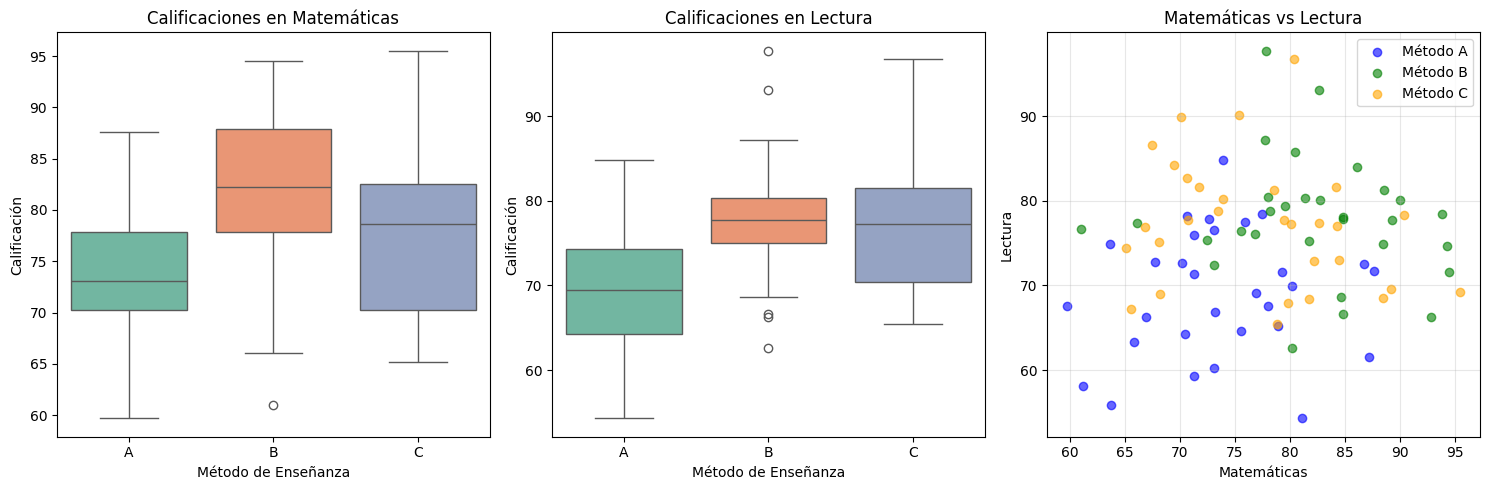

In [ ]:
# Visualización
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Boxplot Matemáticas
sns.boxplot(x='Metodo', y='Matematicas', data=df, ax=axes[0], palette='Set2')
axes[0].set_title('Calificaciones en Matemáticas')
axes[0].set_xlabel('Método de Enseñanza')
axes[0].set_ylabel('Calificación')

# Boxplot Lectura
sns.boxplot(x='Metodo', y='Lectura', data=df, ax=axes[1], palette='Set2')
axes[1].set_title('Calificaciones en Lectura')
axes[1].set_xlabel('Método de Enseñanza')
axes[1].set_ylabel('Calificación')

# Scatter plot Matemáticas vs Lectura
colors = {'A': 'blue', 'B': 'green', 'C': 'orange'}
for metodo in df['Metodo'].unique():
    subset = df[df['Metodo'] == metodo]
    axes[2].scatter(subset['Matematicas'], subset['Lectura'],
                    alpha=0.6, label=f'Método {metodo}', color=colors[metodo])
axes[2].set_xlabel('Matemáticas')
axes[2].set_ylabel('Lectura')
axes[2].set_title('Matemáticas vs Lectura')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

MATRIZ DE CORRELACIÓN

             Matematicas  Lectura
Matematicas       1.0000   0.0886
Lectura           0.0886   1.0000


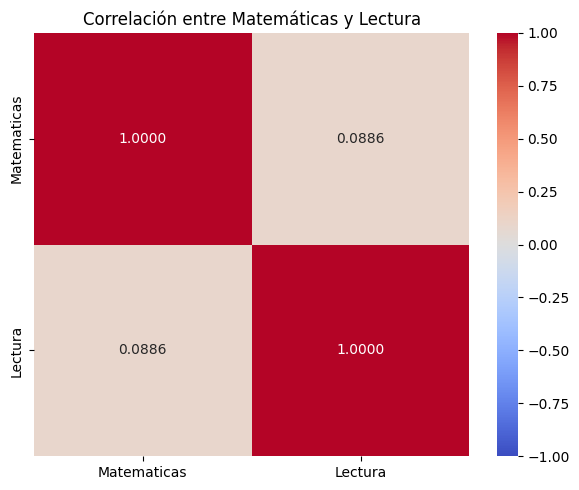

In [ ]:
# Matriz de correlación
print("MATRIZ DE CORRELACIÓN\n")
print(df[['Matematicas', 'Lectura']].corr().round(4))

# Visualización
plt.figure(figsize=(6, 5))
sns.heatmap(df[['Matematicas', 'Lectura']].corr(),
            annot=True, cmap='coolwarm', center=0,
            vmin=-1, vmax=1, fmt='.4f')
plt.title('Correlación entre Matemáticas y Lectura')
plt.tight_layout()
plt.show()

In [ ]:
#  MANOVA - Prueba principal
print("MANOVA \n")

# Ajustar MANOVA
manova = MANOVA.from_formula('Matematicas + Lectura ~ Metodo', data=df)
resultado = manova.mv_test()

print(resultado)

MANOVA 

                   Multivariate linear model
                                                               
---------------------------------------------------------------
       Intercept         Value  Num DF  Den DF  F Value  Pr > F
---------------------------------------------------------------
          Wilks' lambda  0.0146 2.0000 86.0000 2907.3547 0.0000
         Pillai's trace  0.9854 2.0000 86.0000 2907.3547 0.0000
 Hotelling-Lawley trace 67.6129 2.0000 86.0000 2907.3547 0.0000
    Roy's greatest root 67.6129 2.0000 86.0000 2907.3547 0.0000
---------------------------------------------------------------
                                                               
---------------------------------------------------------------
           Metodo         Value  Num DF  Den DF  F Value Pr > F
---------------------------------------------------------------
            Wilks' lambda 0.6317 4.0000 172.0000 11.1040 0.0000
           Pillai's trace 0.3790 4.0000 174.0000 1

In [ ]:
#  Extraer resultados de los cuatro estadísticos
print("=== RESULTADOS DE LOS CUATRO ESTADÍSTICOS ===\n")

# Extraer resultados del MANOVA
resultados_mv = manova.mv_test().results['Metodo']['stat']

print("Estadísticos de prueba:")
print(resultados_mv.round(4))

=== RESULTADOS DE LOS CUATRO ESTADÍSTICOS ===

Estadísticos de prueba:
                           Value Num DF      Den DF    F Value Pr > F
Wilks' lambda           0.631651      4       172.0  11.104044    0.0
Pillai's trace          0.379027    4.0       174.0  10.171469    0.0
Hotelling-Lawley trace  0.566246      4  102.169014  12.128592    0.0
Roy's greatest root     0.534625      2          87  23.256178    0.0


In [ ]:
# Interpretación de resultados
print("=== INTERPRETACIÓN DE RESULTADOS ===\n")

# Verificar significancia de cada estadístico
for estadistico in resultados_mv.index:
    if 'Pr > F' in resultados_mv.columns:
        p_valor = float(resultados_mv.loc[estadistico, 'Pr > F'])
        valor = float(resultados_mv.loc[estadistico, 'Value'])

        if p_valor < 0.05:
            print(f"✅ {estadistico}: Valor = {valor:.4f}, p = {p_valor:.4f} → SIGNIFICATIVO")
        else:
            print(f"❌ {estadistico}: Valor = {valor:.4f}, p = {p_valor:.4f} → NO SIGNIFICATIVO")

print("\n Conclusión:")
print("Si todos los estadísticos son significativos (p < 0.05),")
print("existe evidencia de que los métodos de enseñanza difieren")
print("en el patrón conjunto de Matemáticas y Lectura.")

=== INTERPRETACIÓN DE RESULTADOS ===

✅ Wilks' lambda: Valor = 0.6317, p = 0.0000 → SIGNIFICATIVO
✅ Pillai's trace: Valor = 0.3790, p = 0.0000 → SIGNIFICATIVO
✅ Hotelling-Lawley trace: Valor = 0.5662, p = 0.0000 → SIGNIFICATIVO
✅ Roy's greatest root: Valor = 0.5346, p = 0.0000 → SIGNIFICATIVO

 Conclusión:
Si todos los estadísticos son significativos (p < 0.05),
existe evidencia de que los métodos de enseñanza difieren
en el patrón conjunto de Matemáticas y Lectura.


In [ ]:
# ANOVA univariado post-hoc (con corrección de Bonferroni)
print("=== ANOVA UNIVARIADO POST-HOC ===\n")

# ANOVA para Matemáticas
print("ANOVA para Matemáticas:")
modelo_mat = ols('Matematicas ~ Metodo', data=df).fit()
anova_mat = sm.stats.anova_lm(modelo_mat, typ=2)
print(anova_mat.round(4))

# ANOVA para Lectura
print("\n ANOVA para Lectura:")
modelo_lec = ols('Lectura ~ Metodo', data=df).fit()
anova_lec = sm.stats.anova_lm(modelo_lec, typ=2)
print(anova_lec.round(4))

# Corrección de Bonferroni
alpha = 0.05
alpha_bonferroni = alpha / 2  # 2 variables dependientes

print(f"\n Corrección de Bonferroni:")
print(f"   α original = {alpha}")
print(f"   α ajustado = {alpha_bonferroni}")

# Interpretación
p_mat = anova_mat.loc['Metodo', 'PR(>F)']
p_lec = anova_lec.loc['Metodo', 'PR(>F)']

print(f"\n   Matemáticas: p = {p_mat:.4f} → {'Significativo' if p_mat < alpha_bonferroni else 'No significativo'}")
print(f"   Lectura: p = {p_lec:.4f} → {'Significativo' if p_lec < alpha_bonferroni else 'No significativo'}")

=== ANOVA UNIVARIADO POST-HOC ===

ANOVA para Matemáticas:


             sum_sq    df      F  PR(>F)
Metodo    1117.7714   2.0  9.215  0.0002
Residual  5276.5085  87.0    NaN     NaN

 ANOVA para Lectura:
             sum_sq    df        F  PR(>F)
Metodo    1451.7091   2.0  13.1348     0.0
Residual  4807.8024  87.0      NaN     NaN

 Corrección de Bonferroni:
   α original = 0.05
   α ajustado = 0.025

   Matemáticas: p = 0.0002 → Significativo
   Lectura: p = 0.0000 → Significativo


In [ ]:
#  Comparaciones múltiples post-hoc (Tukey HSD)
print(" COMPARACIONES MÚLTIPLES POST-HOC (TUKEY HSD) \n")

# Tukey para Matemáticas
print("Tukey HSD para Matemáticas:")
tukey_mat = pairwise_tukeyhsd(df['Matematicas'], df['Metodo'], alpha=0.05)
print(tukey_mat)

print("\n Tukey HSD para Lectura:")
tukey_lec = pairwise_tukeyhsd(df['Lectura'], df['Metodo'], alpha=0.05)
print(tukey_lec)

 COMPARACIONES MÚLTIPLES POST-HOC (TUKEY HSD) 

Tukey HSD para Matemáticas:


Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     A      B   8.6083 0.0001  3.8136 13.403   True
     A      C   3.7455 0.1558 -1.0492 8.5402  False
     B      C  -4.8627 0.0461 -9.6574 -0.068   True
---------------------------------------------------

 Tukey HSD para Lectura:


Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     A      B   8.8073    0.0  4.2305 13.3841   True
     A      C   8.1996 0.0001  3.6228 12.7764   True
     B      C  -0.6077 0.9463 -5.1845  3.9691  False
----------------------------------------------------


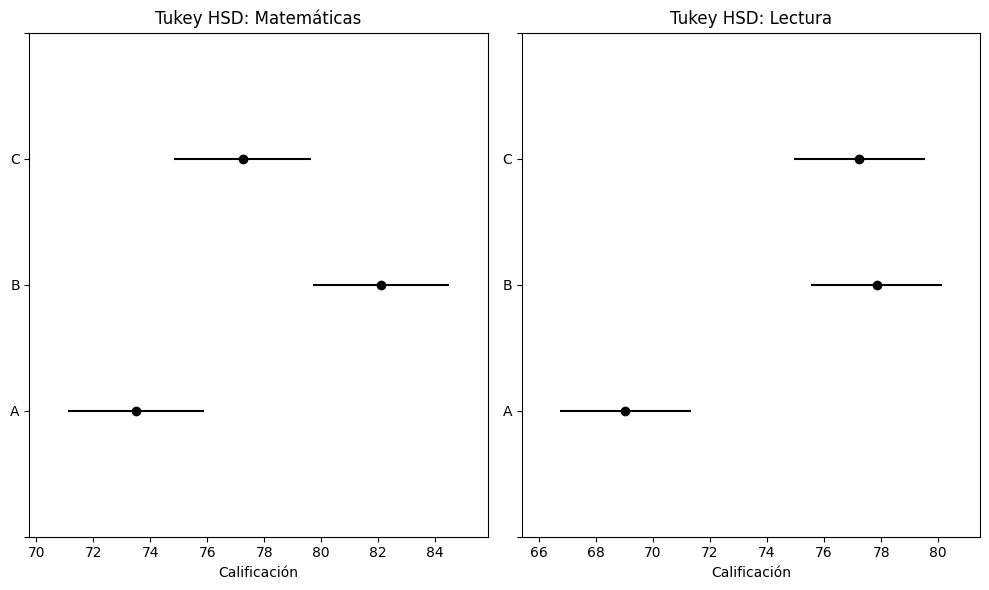

In [ ]:
# Visualización de Tukey HSD
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Tukey Matemáticas
tukey_mat.plot_simultaneous(ax=axes[0])
axes[0].set_title('Tukey HSD: Matemáticas')
axes[0].set_xlabel('Calificación')

# Tukey Lectura
tukey_lec.plot_simultaneous(ax=axes[1])
axes[1].set_title('Tukey HSD: Lectura')
axes[1].set_xlabel('Calificación')

plt.tight_layout()
plt.show()

In [ ]:
# Verificación de supuestos - Normalidad multivariada
print("=== VERIFICACIÓN DE SUPUESTOS ===\n")
print("--- Normalidad Multivariada ---\n")

# Test de Mardia para normalidad multivariada
def mardia_test(data, alpha=0.05):
    """
    Implementación simplificada del test de Mardia
    """
    n, p = data.shape
    mean = np.mean(data, axis=0)
    centered = data - mean
    S = np.cov(data, rowvar=False)
    S_inv = np.linalg.inv(S)

    # Asimetría multivariada
    b1p = 0
    for i in range(n):
        for j in range(n):
            b1p += (centered[i] @ S_inv @ centered[j])**3
    b1p = b1p / (n**2)

    # Curtosis multivariada
    b2p = 0
    for i in range(n):
        b2p += (centered[i] @ S_inv @ centered[i])**2
    b2p = b2p / n

    # Estadísticos de prueba
    skewness_stat = n * b1p / 6
    kurtosis_stat = (b2p - p*(p+2)) / np.sqrt(8*p*(p+2)/n)

    # p-valores
    p_skewness = 1 - stats.chi2.cdf(skewness_stat, p*(p+1)*(p+2)/6)
    p_kurtosis = 2 * (1 - stats.norm.cdf(abs(kurtosis_stat)))

    return {
        'Skewness statistic': skewness_stat,
        'Skewness p-value': p_skewness,
        'Kurtosis statistic': kurtosis_stat,
        'Kurtosis p-value': p_kurtosis
    }

# Aplicar test por grupo
for metodo in df['Metodo'].unique():
    subset = df[df['Metodo'] == metodo][['Matematicas', 'Lectura']].values
    print(f"Método {metodo}:")
    resultado = mardia_test(subset)
    for key, value in resultado.items():
        print(f"  {key}: {value:.4f}")

    if resultado['Skewness p-value'] > 0.05 and resultado['Kurtosis p-value'] > 0.05:
        print("  ✅ Normalidad multivariada aceptable")
    else:
        print("  ⚠️ Posible violación de normalidad multivariada")
    print()

=== VERIFICACIÓN DE SUPUESTOS ===

--- Normalidad Multivariada ---

Método A:
  Skewness statistic: 1.9333
  Skewness p-value: 0.7480
  Kurtosis statistic: -1.1241
  Kurtosis p-value: 0.2610
  ✅ Normalidad multivariada aceptable

Método B:
  Skewness statistic: 4.0213
  Skewness p-value: 0.4031
  Kurtosis statistic: -0.2271
  Kurtosis p-value: 0.8203
  ✅ Normalidad multivariada aceptable

Método C:
  Skewness statistic: 3.1460
  Skewness p-value: 0.5337
  Kurtosis statistic: -0.9106
  Kurtosis p-value: 0.3625
  ✅ Normalidad multivariada aceptable



In [ ]:
#  Verificación de supuestos - Homogeneidad de covarianzas (Box's M)
print(" Homogeneidad de Matrices de Covarianza (Box's M) \n")

def box_m_test(data, groups):
    """
    Implementación del test M de Box
    """
    group_names = groups.unique()
    k = len(group_names)
    p = data.shape[1]

    # Tamaños de muestra
    ns = [len(data[groups == g]) for g in group_names]
    n_total = sum(ns)

    # Matrices de covarianza por grupo
    covs = []
    for g in group_names:
        subset = data[groups == g]
        covs.append(np.cov(subset, rowvar=False))

    # Covarianza pooled
    pooled_cov = sum([(n-1) * cov for n, cov in zip(ns, covs)]) / (n_total - k)

    # Estadístico M
    M = (n_total - k) * np.log(np.linalg.det(pooled_cov))
    for n, cov in zip(ns, covs):
        M -= (n - 1) * np.log(np.linalg.det(cov))

    # Factor de corrección
    c = (2 * p**2 + 3 * p - 1) / (6 * (p + 1) * (k - 1))
    c *= sum([1/(n-1) for n in ns]) - 1/(n_total - k)

    # Estadístico de prueba
    chi2_stat = M * (1 - c)

    # Grados de libertad
    df = p * (p + 1) * (k - 1) / 2

    # p-valor
    p_value = 1 - stats.chi2.cdf(chi2_stat, df)

    return {
        'M statistic': M,
        'Chi-square': chi2_stat,
        'df': df,
        'p-value': p_value
    }

# Aplicar Box's M
resultado_box = box_m_test(df[['Matematicas', 'Lectura']], df['Metodo'])
print("Resultados del test M de Box:")
for key, value in resultado_box.items():
    print(f"  {key}: {value:.4f}")

if resultado_box['p-value'] > 0.05:
    print("\n✅ No se rechaza H₀: Las matrices de covarianza son homogéneas")
else:
    print("\n⚠️ Se rechaza H₀: Posible violación de homogeneidad de covarianzas")
    print("   → Considerar usar Pillai's Trace (más robusto)")

 Homogeneidad de Matrices de Covarianza (Box's M) 

Resultados del test M de Box:
  M statistic: 2.3240
  Chi-square: 2.2469
  df: 6.0000
  p-value: 0.8957

✅ No se rechaza H₀: Las matrices de covarianza son homogéneas


=== LDA vs MANOVA: DATOS SINTÉTICOS ===

Autovalores de E⁻¹H: [0.5346 0.0316]
Wilks            = Π 1/(1+λ)  : 0.6317
Pillai           = Σ λ/(1+λ)  : 0.379
Hotelling-Lawley = Σ λ        : 0.5662
Roy              = λ máximo   : 0.5346

% de separación por eje discriminante: [94.4  5.6]

Coeficientes discriminantes estandarizados:
               LD1    LD2
Matematicas -0.684  0.737
Lectura     -0.806 -0.602

Exactitud de clasificación (resustitución): 0.567


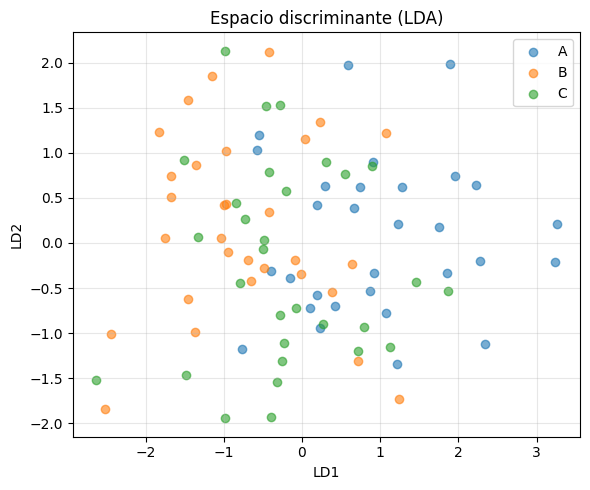

In [ ]:
# LDA y su relación con MANOVA (apoyo a la pregunta 5)
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

def lda_vs_manova(data, vars_, grupo):
    X = data[vars_].values; y = data[grupo].values
    gs = np.unique(y); k = len(gs); s = min(len(vars_), k - 1)
    gm = X.mean(axis=0)
    # H = suma de cuadrados entre grupos, E = suma de cuadrados dentro de grupos
    H = sum(len(X[y==g]) * np.outer(X[y==g].mean(0)-gm, X[y==g].mean(0)-gm) for g in gs)
    E = sum((X[y==g]-X[y==g].mean(0)).T @ (X[y==g]-X[y==g].mean(0)) for g in gs)
    lam = np.sort(np.linalg.eigvals(np.linalg.inv(E) @ H).real)[::-1][:s]
    print("Autovalores de E⁻¹H:", lam.round(4))
    print("Wilks            = Π 1/(1+λ)  :", round(np.prod(1/(1+lam)), 4))
    print("Pillai           = Σ λ/(1+λ)  :", round(np.sum(lam/(1+lam)), 4))
    print("Hotelling-Lawley = Σ λ        :", round(lam.sum(), 4))
    print("Roy              = λ máximo   :", round(lam[0], 4))

    lda = LDA().fit(X, y)
    print("\n% de separación por eje discriminante:", (lda.explained_variance_ratio_*100).round(1))
    sw = np.sqrt(np.diag(E) / (len(y) - k))   # desv. estándar dentro de grupos
    coef = pd.DataFrame(lda.scalings_[:, :s] * sw[:, None], index=vars_,
                        columns=[f'LD{i+1}' for i in range(s)]).round(3)
    print("\nCoeficientes discriminantes estandarizados:"); print(coef)
    print("\nExactitud de clasificación (resustitución):", round(lda.score(X, y), 3))

    Z = lda.transform(X)
    plt.figure(figsize=(6, 5))
    for g in gs:
        plt.scatter(Z[y==g, 0], Z[y==g, 1] if s > 1 else np.zeros((y==g).sum()), alpha=0.6, label=g)
    plt.xlabel('LD1'); plt.ylabel('LD2' if s > 1 else ''); plt.title('Espacio discriminante (LDA)')
    plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()
    return lda

print("=== LDA vs MANOVA: DATOS SINTÉTICOS ===\n")
lda_sint = lda_vs_manova(df, ['Matematicas', 'Lectura'], 'Metodo')


In [ ]:
#  Preguntas de análisis
print(" PREGUNTAS DE ANÁLISIS:")
print("\n1. ¿Cuál de los cuatro estadísticos MANOVA es más apropiado y por qué?")
print("2. ¿Qué variable dependiente contribuye más a las diferencias entre grupos?")
print("3. ¿Qué pares de grupos son significativamente diferentes?")
print("4. ¿Se cumplen los supuestos del MANOVA? ¿Qué implicaciones tiene?")
print("5. ¿Cómo se relacionan los resultados del LDA con los del MANOVA?")



 PREGUNTAS DE ANÁLISIS:

1. ¿Cuál de los cuatro estadísticos MANOVA es más apropiado y por qué?
2. ¿Qué variable dependiente contribuye más a las diferencias entre grupos?
3. ¿Qué pares de grupos son significativamente diferentes?
4. ¿Se cumplen los supuestos del MANOVA? ¿Qué implicaciones tiene?
5. ¿Cómo se relacionan los resultados del LDA con los del MANOVA?


**Escribe tus respuestas aquí:** *(datos sintéticos: métodos de enseñanza)*

**1. ¿Cuál de los cuatro estadísticos es más apropiado?**
La **traza de Pillai** (V = 0.379, F(4, 174) = 10.17, p < 0.001). Es el más robusto ante desviaciones de normalidad y de homogeneidad de covarianzas, y el diseño está balanceado (30 por grupo). Aquí los cuatro coinciden (todos p < 0.001), así que la conclusión no depende de la elección; Roy es el menos recomendable como prueba única porque solo usa la primera raíz y es el más sensible a violaciones de supuestos.

**2. ¿Qué variable contribuye más a las diferencias?**
**Lectura**, por poco. ANOVA: F = 13.13 (η² = 0.232) contra F = 9.22 (η² = 0.175) de Matemáticas, y en el LDA su coeficiente estandarizado en LD1 es mayor (|−0.806| vs |−0.684|). Ambas son significativas con Bonferroni (α = 0.025).

**3. ¿Qué pares de grupos difieren significativamente? (Tukey, α = 0.05)**
- Matemáticas: **A–B** (diferencia 8.61, p = 0.0001) y **B–C** (−4.86, p = 0.046, marginal). A–C no (p = 0.156).
- Lectura: **A–B** (8.81, p < 0.001) y **A–C** (8.20, p = 0.0001). B–C no (p = 0.946).

El método B tiene las medias más altas en ambas variables; A es el más bajo. Solo A–B difiere en las dos variables a la vez.

**4. ¿Se cumplen los supuestos?**
Sí. Mardia: los tres grupos tienen p > 0.05 en asimetría (0.75, 0.40, 0.53) y curtosis (0.26, 0.82, 0.36). Box's M: χ² = 2.25, gl = 6, p = 0.896, así que las covarianzas son homogéneas. Implicación: el MANOVA es válido y cualquiera de los cuatro estadísticos sirve. Esto era de esperarse porque los datos se simularon normales con la misma varianza (σ = 8). Un detalle: Matemáticas y Lectura casi no correlacionan (r = 0.089), por lo que el MANOVA aporta poco más que los dos ANOVA por separado.

**5. ¿Cómo se relaciona el LDA con el MANOVA?**
Son el mismo problema visto desde dos lados: ambos parten de los autovalores de E⁻¹H (λ₁ = 0.5346, λ₂ = 0.0316). Los cuatro estadísticos del MANOVA son funciones de esos λ (Wilks = Π 1/(1+λ) = 0.6317, Pillai = Σ λ/(1+λ) = 0.3790, Hotelling-Lawley = Σλ = 0.5662, Roy = λ₁ = 0.5346; coinciden con la salida de `statsmodels`) y los ejes del LDA son sus autovectores. El MANOVA responde *si* los grupos difieren; el LDA dice *en qué combinación* y *qué tan bien se clasifican*. Aquí LD1 explica 94.4% de la separación y pondera las dos variables con el mismo signo (un eje de «desempeño general»); LD2 (5.6%) es un contraste Matemáticas vs Lectura, casi despreciable. La exactitud de clasificación es 56.7% (azar = 33.3%): el efecto es real pero los grupos se traslapan bastante.


# Actividad MANOVA

Ahora repite todo para el siguiente dataset de load_iris

In [ ]:
# Celda 3: Cargar el dataset Iris (datos reales)
# El dataset Iris contiene mediciones de 3 especies de flores
iris = load_iris()

# Crear DataFrame
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['Especie'] = iris.target_names[iris.target]

# Renombrar columnas para claridad
df.columns = ['Longitud_Sepalo', 'Ancho_Sepalo',
              'Longitud_Petalo', 'Ancho_Petalo', 'Especie']

print(f"Forma del dataset: {df.shape}")
print(f"Especies: {df['Especie'].unique()}")
print(f"Observaciones por especie:")
print(df['Especie'].value_counts())
df.head(10)

Forma del dataset: (150, 5)
Especies: <StringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str
Observaciones por especie:
Especie
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,Longitud_Sepalo,Ancho_Sepalo,Longitud_Petalo,Ancho_Petalo,Especie
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa


In [ ]:
#  Estadísticas descriptivas por especie
print("ESTADÍSTICAS DESCRIPTIVAS POR ESPECIE: \n")
vars_iris = ['Longitud_Sepalo', 'Ancho_Sepalo', 'Longitud_Petalo', 'Ancho_Petalo']
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)

estadisticas = df.groupby('Especie').agg({v: ['mean', 'std', 'min', 'max'] for v in vars_iris}).round(2)
print(estadisticas)

ESTADÍSTICAS DESCRIPTIVAS POR ESPECIE: 

           Longitud_Sepalo                 Ancho_Sepalo                 Longitud_Petalo                 Ancho_Petalo                
                      mean   std  min  max         mean   std  min  max            mean   std  min  max         mean   std  min  max
Especie                                                                                                                             
setosa                5.01  0.35  4.3  5.8         3.43  0.38  2.3  4.4            1.46  0.17  1.0  1.9         0.25  0.11  0.1  0.6
versicolor            5.94  0.52  4.9  7.0         2.77  0.31  2.0  3.4            4.26  0.47  3.0  5.1         1.33  0.20  1.0  1.8
virginica             6.59  0.64  4.9  7.9         2.97  0.32  2.2  3.8            5.55  0.55  4.5  6.9         2.03  0.27  1.4  2.5


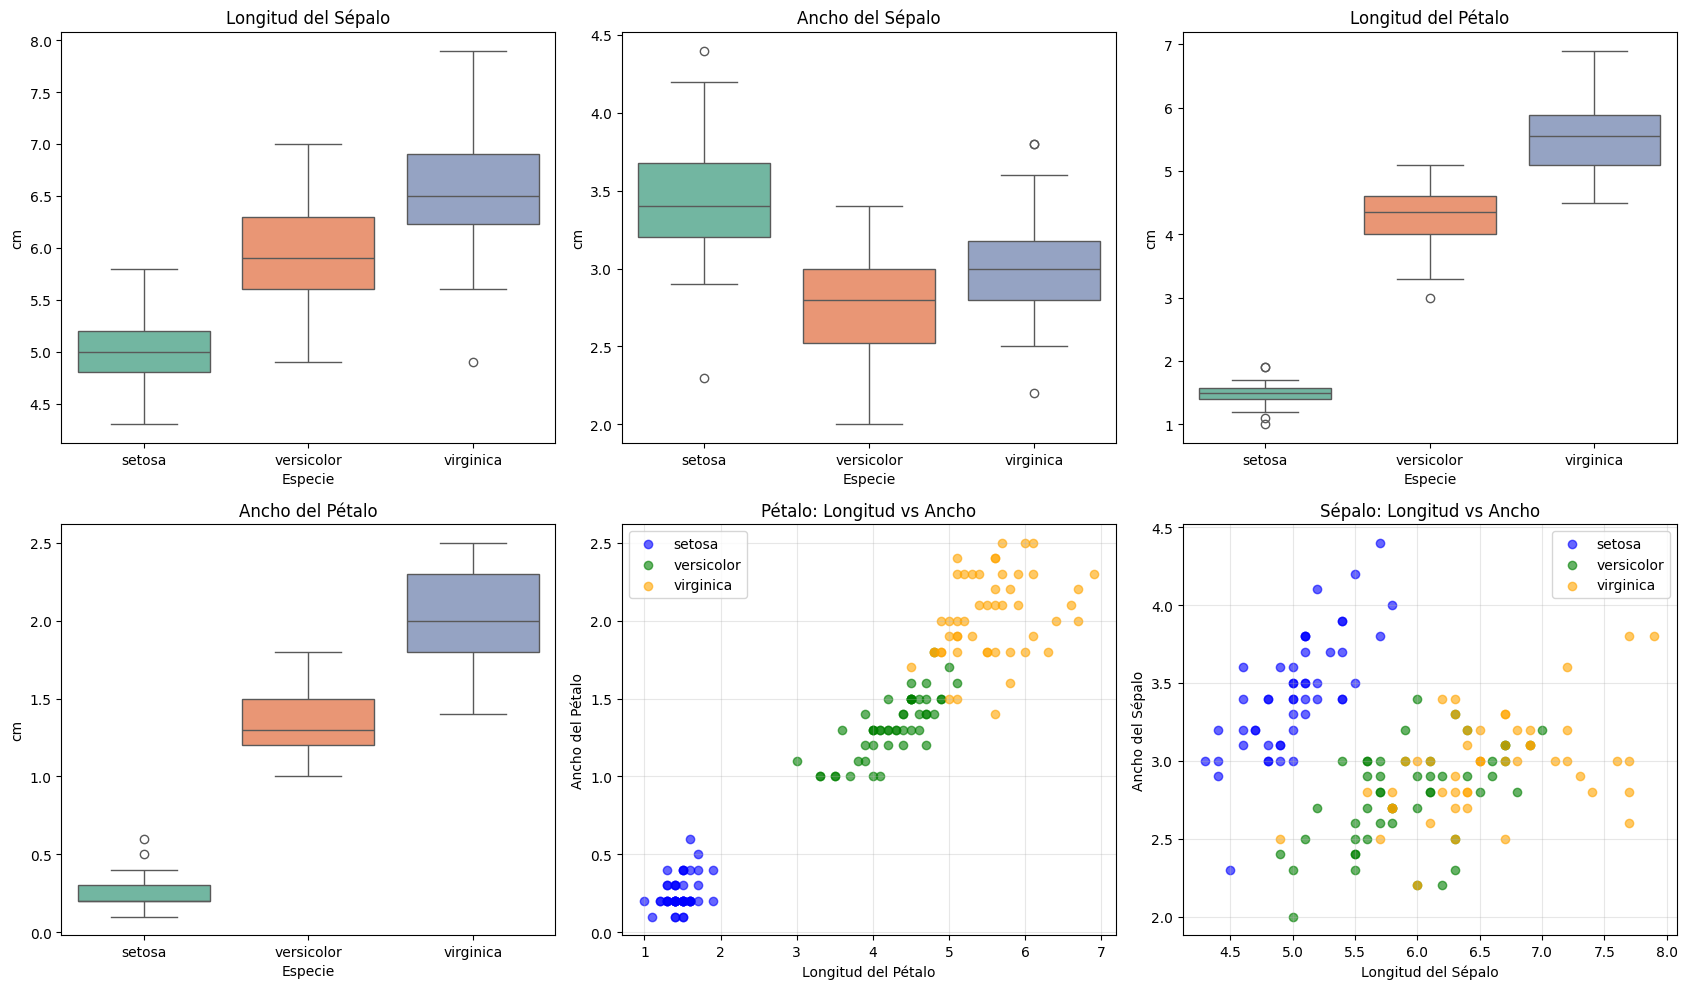

In [ ]:
# Visualización
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.ravel()

titulos = ['Longitud del Sépalo', 'Ancho del Sépalo', 'Longitud del Pétalo', 'Ancho del Pétalo']
for i, v in enumerate(vars_iris):
    sns.boxplot(x='Especie', y=v, data=df, ax=axes[i], palette='Set2')
    axes[i].set_title(titulos[i])
    axes[i].set_xlabel('Especie')
    axes[i].set_ylabel('cm')

# Scatter Longitud vs Ancho del Pétalo
colors = {'setosa': 'blue', 'versicolor': 'green', 'virginica': 'orange'}
for esp in df['Especie'].unique():
    subset = df[df['Especie'] == esp]
    axes[4].scatter(subset['Longitud_Petalo'], subset['Ancho_Petalo'],
                    alpha=0.6, label=esp, color=colors[esp])
    axes[5].scatter(subset['Longitud_Sepalo'], subset['Ancho_Sepalo'],
                    alpha=0.6, label=esp, color=colors[esp])
axes[4].set_xlabel('Longitud del Pétalo'); axes[4].set_ylabel('Ancho del Pétalo')
axes[4].set_title('Pétalo: Longitud vs Ancho'); axes[4].legend(); axes[4].grid(True, alpha=0.3)
axes[5].set_xlabel('Longitud del Sépalo'); axes[5].set_ylabel('Ancho del Sépalo')
axes[5].set_title('Sépalo: Longitud vs Ancho'); axes[5].legend(); axes[5].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

MATRIZ DE CORRELACIÓN

                 Longitud_Sepalo  Ancho_Sepalo  Longitud_Petalo  Ancho_Petalo
Longitud_Sepalo           1.0000       -0.1176           0.8718        0.8179
Ancho_Sepalo             -0.1176        1.0000          -0.4284       -0.3661
Longitud_Petalo           0.8718       -0.4284           1.0000        0.9629
Ancho_Petalo              0.8179       -0.3661           0.9629        1.0000


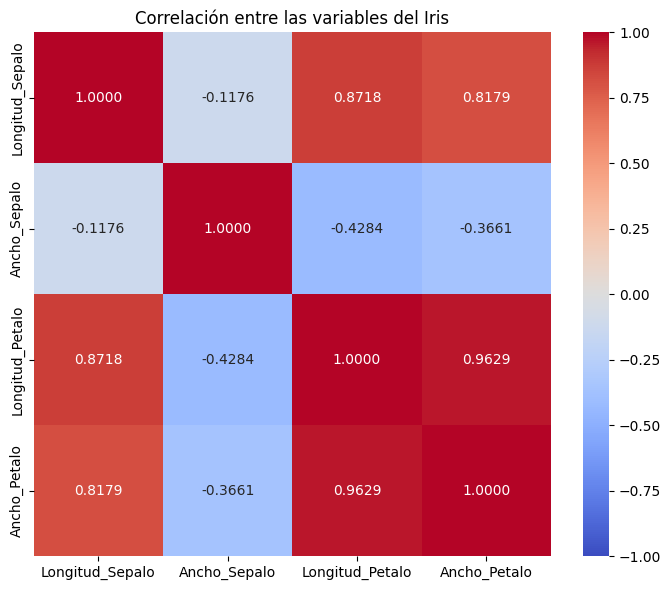

In [ ]:
# Matriz de correlación
print("MATRIZ DE CORRELACIÓN\n")
print(df[vars_iris].corr().round(4))

# Visualización
plt.figure(figsize=(7, 6))
sns.heatmap(df[vars_iris].corr(),
            annot=True, cmap='coolwarm', center=0,
            vmin=-1, vmax=1, fmt='.4f')
plt.title('Correlación entre las variables del Iris')
plt.tight_layout()
plt.show()

In [ ]:
#  MANOVA - Prueba principal
print("MANOVA \n")

# Ajustar MANOVA
manova = MANOVA.from_formula('Longitud_Sepalo + Ancho_Sepalo + Longitud_Petalo + Ancho_Petalo ~ Especie', data=df)
resultado = manova.mv_test()

print(resultado)

MANOVA 

                   Multivariate linear model
                                                                
----------------------------------------------------------------
       Intercept         Value  Num DF  Den DF   F Value  Pr > F
----------------------------------------------------------------
          Wilks' lambda  0.0170 4.0000 144.0000 2086.7720 0.0000
         Pillai's trace  0.9830 4.0000 144.0000 2086.7720 0.0000
 Hotelling-Lawley trace 57.9659 4.0000 144.0000 2086.7720 0.0000
    Roy's greatest root 57.9659 4.0000 144.0000 2086.7720 0.0000
----------------------------------------------------------------
                                                                
----------------------------------------------------------------
        Especie          Value  Num DF  Den DF   F Value  Pr > F
----------------------------------------------------------------
          Wilks' lambda  0.0234 8.0000 288.0000  199.1453 0.0000
         Pillai's trace  1.1919 8.00

In [ ]:
#  Extraer resultados de los cuatro estadísticos
print("=== RESULTADOS DE LOS CUATRO ESTADÍSTICOS ===\n")

# Extraer resultados del MANOVA
resultados_mv = manova.mv_test().results['Especie']['stat']

print("Estadísticos de prueba:")
print(resultados_mv.round(4))

=== RESULTADOS DE LOS CUATRO ESTADÍSTICOS ===

Estadísticos de prueba:
                            Value Num DF     Den DF      F Value Pr > F
Wilks' lambda            0.023439      8      288.0   199.145344    0.0
Pillai's trace           1.191899    8.0      290.0    53.466489    0.0
Hotelling-Lawley trace   32.47732      8  203.40239   582.197018    0.0
Roy's greatest root     32.191929      4        145  1166.957433    0.0


In [ ]:
# Interpretación de resultados
print("=== INTERPRETACIÓN DE RESULTADOS ===\n")

# Verificar significancia de cada estadístico
for estadistico in resultados_mv.index:
    if 'Pr > F' in resultados_mv.columns:
        p_valor = float(resultados_mv.loc[estadistico, 'Pr > F'])
        valor = float(resultados_mv.loc[estadistico, 'Value'])

        if p_valor < 0.05:
            print(f"✅ {estadistico}: Valor = {valor:.4f}, p = {p_valor:.4e} → SIGNIFICATIVO")
        else:
            print(f"❌ {estadistico}: Valor = {valor:.4f}, p = {p_valor:.4e} → NO SIGNIFICATIVO")

print("\n Conclusión:")
print("Si todos los estadísticos son significativos (p < 0.05),")
print("existe evidencia de que las especies difieren")
print("en el patrón conjunto de las cuatro medidas florales.")

=== INTERPRETACIÓN DE RESULTADOS ===

✅ Wilks' lambda: Valor = 0.0234, p = 1.3650e-112 → SIGNIFICATIVO
✅ Pillai's trace: Valor = 1.1919, p = 9.7422e-53 → SIGNIFICATIVO
✅ Hotelling-Lawley trace: Valor = 32.4773, p = 1.0774e-135 → SIGNIFICATIVO
✅ Roy's greatest root: Valor = 32.1919, p = 3.7873e-109 → SIGNIFICATIVO

 Conclusión:
Si todos los estadísticos son significativos (p < 0.05),
existe evidencia de que las especies difieren
en el patrón conjunto de las cuatro medidas florales.


In [ ]:
# ANOVA univariado post-hoc (con corrección de Bonferroni)
print("=== ANOVA UNIVARIADO POST-HOC ===\n")

anovas = {}
for v in vars_iris:
    print(f"ANOVA para {v}:")
    modelo = ols(f'{v} ~ Especie', data=df).fit()
    anovas[v] = sm.stats.anova_lm(modelo, typ=2)
    print(anovas[v].round(4))
    print()

# Corrección de Bonferroni
alpha = 0.05
alpha_bonferroni = alpha / len(vars_iris)  # 4 variables dependientes

print(f"Corrección de Bonferroni:")
print(f"   α original = {alpha}")
print(f"   α ajustado = {alpha_bonferroni}")

# Interpretación (con tamaño de efecto η²)
print()
for v in vars_iris:
    p = anovas[v].loc['Especie', 'PR(>F)']
    eta2 = anovas[v].loc['Especie', 'sum_sq'] / anovas[v]['sum_sq'].sum()
    print(f"   {v}: F = {anovas[v].loc['Especie','F']:.2f}, p = {p:.2e}, η² = {eta2:.3f} → {'Significativo' if p < alpha_bonferroni else 'No significativo'}")

=== ANOVA UNIVARIADO POST-HOC ===

ANOVA para Longitud_Sepalo:
           sum_sq     df         F  PR(>F)
Especie   63.2121    2.0  119.2645     0.0
Residual  38.9562  147.0       NaN     NaN

ANOVA para Ancho_Sepalo:
           sum_sq     df      F  PR(>F)
Especie   11.3449    2.0  49.16     0.0
Residual  16.9620  147.0    NaN     NaN

ANOVA para Longitud_Petalo:
            sum_sq     df          F  PR(>F)
Especie   437.1028    2.0  1180.1612     0.0
Residual   27.2226  147.0        NaN     NaN

ANOVA para Ancho_Petalo:
           sum_sq     df         F  PR(>F)
Especie   80.4133    2.0  960.0071     0.0
Residual   6.1566  147.0       NaN     NaN

Corrección de Bonferroni:
   α original = 0.05
   α ajustado = 0.0125

   Longitud_Sepalo: F = 119.26, p = 1.67e-31, η² = 0.619 → Significativo
   Ancho_Sepalo: F = 49.16, p = 4.49e-17, η² = 0.401 → Significativo
   Longitud_Petalo: F = 1180.16, p = 2.86e-91, η² = 0.941 → Significativo
   Ancho_Petalo: F = 960.01, p = 4.17e-85, η² = 0.929 →

In [ ]:
#  Comparaciones múltiples post-hoc (Tukey HSD)
print(" COMPARACIONES MÚLTIPLES POST-HOC (TUKEY HSD) \n")

tukeys = {}
for v in vars_iris:
    print(f"Tukey HSD para {v}:")
    tukeys[v] = pairwise_tukeyhsd(df[v], df['Especie'], alpha=0.05)
    print(tukeys[v])
    print()

 COMPARACIONES MÚLTIPLES POST-HOC (TUKEY HSD) 

Tukey HSD para Longitud_Sepalo:


   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1     group2   meandiff p-adj lower  upper  reject
---------------------------------------------------------
    setosa versicolor     0.93   0.0 0.6862 1.1738   True
    setosa  virginica    1.582   0.0 1.3382 1.8258   True
versicolor  virginica    0.652   0.0 0.4082 0.8958   True
---------------------------------------------------------

Tukey HSD para Ancho_Sepalo:


    Multiple Comparison of Means - Tukey HSD, FWER=0.05     
  group1     group2   meandiff p-adj   lower   upper  reject
------------------------------------------------------------
    setosa versicolor   -0.658    0.0 -0.8189 -0.4971   True
    setosa  virginica   -0.454    0.0 -0.6149 -0.2931   True
versicolor  virginica    0.204 0.0088  0.0431  0.3649   True
------------------------------------------------------------

Tukey HSD para Longitud_Petalo:


   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1     group2   meandiff p-adj lower  upper  reject
---------------------------------------------------------
    setosa versicolor    2.798   0.0 2.5942 3.0018   True
    setosa  virginica     4.09   0.0 3.8862 4.2938   True
versicolor  virginica    1.292   0.0 1.0882 1.4958   True
---------------------------------------------------------

Tukey HSD para Ancho_Petalo:


   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1     group2   meandiff p-adj lower  upper  reject
---------------------------------------------------------
    setosa versicolor     1.08   0.0 0.9831 1.1769   True
    setosa  virginica     1.78   0.0 1.6831 1.8769   True
versicolor  virginica      0.7   0.0 0.6031 0.7969   True
---------------------------------------------------------



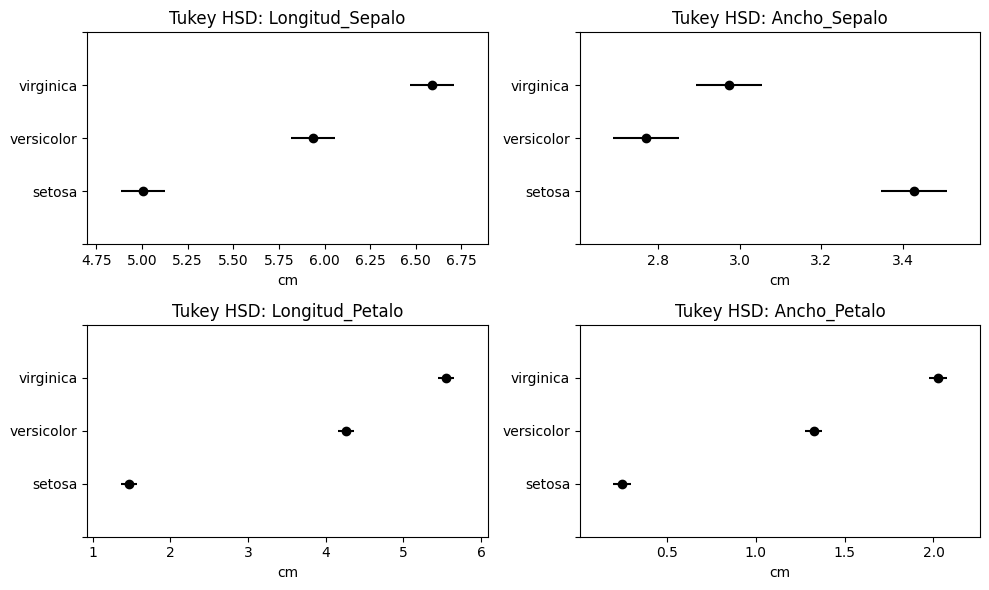

In [ ]:
# Visualización de Tukey HSD
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.ravel()

for i, v in enumerate(vars_iris):
    tukeys[v].plot_simultaneous(ax=axes[i])
    axes[i].set_title(f'Tukey HSD: {v}')
    axes[i].set_xlabel('cm')

plt.tight_layout()
plt.show()

In [ ]:
# Verificación de supuestos - Normalidad multivariada
print("=== VERIFICACIÓN DE SUPUESTOS ===\n")
print("--- Normalidad Multivariada ---\n")

# Test de Mardia para normalidad multivariada
def mardia_test(data, alpha=0.05):
    """
    Implementación simplificada del test de Mardia
    """
    n, p = data.shape
    mean = np.mean(data, axis=0)
    centered = data - mean
    S = np.cov(data, rowvar=False)
    S_inv = np.linalg.inv(S)

    # Asimetría multivariada
    b1p = 0
    for i in range(n):
        for j in range(n):
            b1p += (centered[i] @ S_inv @ centered[j])**3
    b1p = b1p / (n**2)

    # Curtosis multivariada
    b2p = 0
    for i in range(n):
        b2p += (centered[i] @ S_inv @ centered[i])**2
    b2p = b2p / n

    # Estadísticos de prueba
    skewness_stat = n * b1p / 6
    kurtosis_stat = (b2p - p*(p+2)) / np.sqrt(8*p*(p+2)/n)

    # p-valores
    p_skewness = 1 - stats.chi2.cdf(skewness_stat, p*(p+1)*(p+2)/6)
    p_kurtosis = 2 * (1 - stats.norm.cdf(abs(kurtosis_stat)))

    return {
        'Skewness statistic': skewness_stat,
        'Skewness p-value': p_skewness,
        'Kurtosis statistic': kurtosis_stat,
        'Kurtosis p-value': p_kurtosis
    }

# Aplicar test por grupo
for metodo in df['Especie'].unique():
    subset = df[df['Especie'] == metodo][vars_iris].values
    print(f"Especie {metodo}:")
    resultado = mardia_test(subset)
    for key, value in resultado.items():
        print(f"  {key}: {value:.4f}")

    if resultado['Skewness p-value'] > 0.05 and resultado['Kurtosis p-value'] > 0.05:
        print("  ✅ Normalidad multivariada aceptable")
    else:
        print("  ⚠️ Posible violación de normalidad multivariada")
    print()

=== VERIFICACIÓN DE SUPUESTOS ===

--- Normalidad Multivariada ---

Especie setosa:
  Skewness statistic: 24.1551
  Skewness p-value: 0.2357
  Kurtosis statistic: 0.7587
  Kurtosis p-value: 0.4480
  ✅ Normalidad multivariada aceptable

Especie versicolor:
  Skewness statistic: 23.7039
  Skewness p-value: 0.2556
  Kurtosis statistic: -1.0342
  Kurtosis p-value: 0.3010
  ✅ Normalidad multivariada aceptable

Especie virginica:
  Skewness statistic: 24.7257
  Skewness p-value: 0.2121
  Kurtosis statistic: -0.3384
  Kurtosis p-value: 0.7350
  ✅ Normalidad multivariada aceptable



In [ ]:
#  Verificación de supuestos - Homogeneidad de covarianzas (Box's M)
print(" Homogeneidad de Matrices de Covarianza (Box's M) \n")

def box_m_test(data, groups):
    """
    Implementación del test M de Box
    """
    group_names = groups.unique()
    k = len(group_names)
    p = data.shape[1]

    # Tamaños de muestra
    ns = [len(data[groups == g]) for g in group_names]
    n_total = sum(ns)

    # Matrices de covarianza por grupo
    covs = []
    for g in group_names:
        subset = data[groups == g]
        covs.append(np.cov(subset, rowvar=False))

    # Covarianza pooled
    pooled_cov = sum([(n-1) * cov for n, cov in zip(ns, covs)]) / (n_total - k)

    # Estadístico M
    M = (n_total - k) * np.log(np.linalg.det(pooled_cov))
    for n, cov in zip(ns, covs):
        M -= (n - 1) * np.log(np.linalg.det(cov))

    # Factor de corrección
    c = (2 * p**2 + 3 * p - 1) / (6 * (p + 1) * (k - 1))
    c *= sum([1/(n-1) for n in ns]) - 1/(n_total - k)

    # Estadístico de prueba
    chi2_stat = M * (1 - c)

    # Grados de libertad
    df = p * (p + 1) * (k - 1) / 2

    # p-valor
    p_value = 1 - stats.chi2.cdf(chi2_stat, df)

    return {
        'M statistic': M,
        'Chi-square': chi2_stat,
        'df': df,
        'p-value': p_value
    }

# Aplicar Box's M
resultado_box = box_m_test(df[vars_iris], df['Especie'])
print("Resultados del test M de Box:")
for key, value in resultado_box.items():
    print(f"  {key}: {value:.4f}")

if resultado_box['p-value'] > 0.05:
    print("\n✅ No se rechaza H₀: Las matrices de covarianza son homogéneas")
else:
    print("\n⚠️ Se rechaza H₀: Posible violación de homogeneidad de covarianzas")
    print("   → Considerar usar Pillai's Trace (más robusto)")

 Homogeneidad de Matrices de Covarianza (Box's M) 

Resultados del test M de Box:
  M statistic: 146.6632
  Chi-square: 140.9430
  df: 20.0000
  p-value: 0.0000

⚠️ Se rechaza H₀: Posible violación de homogeneidad de covarianzas
   → Considerar usar Pillai's Trace (más robusto)


=== LDA vs MANOVA: IRIS ===

Autovalores de E⁻¹H: [32.1919  0.2854]
Wilks            = Π 1/(1+λ)  : 0.0234
Pillai           = Σ λ/(1+λ)  : 1.1919
Hotelling-Lawley = Σ λ        : 32.4773
Roy              = λ máximo   : 32.1919

% de separación por eje discriminante: [99.1  0.9]

Coeficientes discriminantes estandarizados:
                   LD1    LD2
Longitud_Sepalo  0.427 -0.012
Ancho_Sepalo     0.521 -0.735
Longitud_Petalo -0.947  0.401
Ancho_Petalo    -0.575 -0.581

Exactitud de clasificación (resustitución): 0.98


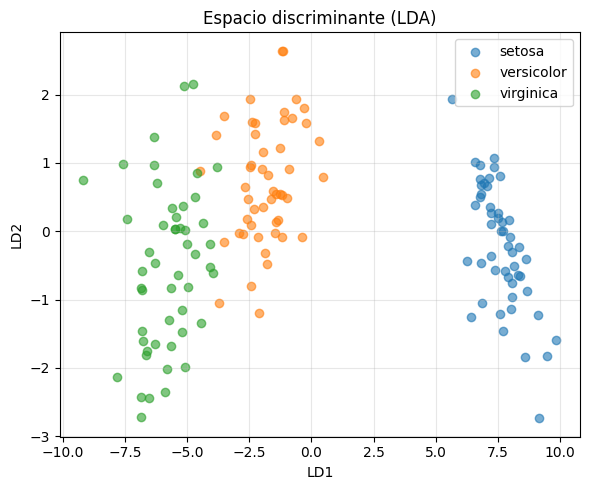

In [ ]:
print("=== LDA vs MANOVA: IRIS ===\n")
lda_iris = lda_vs_manova(df, vars_iris, 'Especie')

In [ ]:
#  Preguntas de análisis
print(" PREGUNTAS DE ANÁLISIS:")
print("\n1. ¿Cuál de los cuatro estadísticos MANOVA es más apropiado y por qué?")
print("2. ¿Qué variable dependiente contribuye más a las diferencias entre grupos?")
print("3. ¿Qué pares de grupos son significativamente diferentes?")
print("4. ¿Se cumplen los supuestos del MANOVA? ¿Qué implicaciones tiene?")
print("5. ¿Cómo se relacionan los resultados del LDA con los del MANOVA?")



 PREGUNTAS DE ANÁLISIS:

1. ¿Cuál de los cuatro estadísticos MANOVA es más apropiado y por qué?
2. ¿Qué variable dependiente contribuye más a las diferencias entre grupos?
3. ¿Qué pares de grupos son significativamente diferentes?
4. ¿Se cumplen los supuestos del MANOVA? ¿Qué implicaciones tiene?
5. ¿Cómo se relacionan los resultados del LDA con los del MANOVA?


**Escribe tus respuestas aquí:** *(Iris: 4 variables, 3 especies, n = 50 por especie)*

**1. ¿Cuál de los cuatro estadísticos es más apropiado?**
La **traza de Pillai** (V = 1.192, F(8, 290) = 53.47, p ≈ 1e-52). Box's M rechaza la homogeneidad de covarianzas (ver pregunta 4), y Pillai es el más robusto ante eso, sobre todo con grupos del mismo tamaño como aquí. Los cuatro estadísticos dan p < 1e-50, así que la conclusión no cambia; además, como λ₁ concentra 99.1% de la separación, Roy y Hotelling-Lawley son casi idénticos (32.19 vs 32.48) y no aportan información distinta.

**2. ¿Qué variable contribuye más a las diferencias?**
**Longitud del pétalo** (F = 1180, η² = 0.941), seguida de cerca por **ancho del pétalo** (F = 960, η² = 0.929). Después vienen longitud del sépalo (η² = 0.619) y ancho del sépalo (η² = 0.401). Todas son significativas con Bonferroni (α = 0.0125). En el LDA, la longitud del pétalo también tiene el mayor coeficiente en LD1 (|−0.947|). Ojo: longitud y ancho del pétalo están casi duplicadas entre sí (r = 0.963), así que su aporte se comparte; y el ancho del sépalo, débil por sí solo, recibe un peso alto en el LDA (0.521) porque aporta información nueva una vez controlados los pétalos.

**3. ¿Qué pares de grupos difieren significativamente?**
**Los tres pares, en las cuatro variables** (Tukey, todos p < 0.01). El caso más débil es versicolor–virginica en ancho del sépalo (diferencia 0.204, p = 0.0088). La separación más grande es setosa–virginica (p. ej. 4.09 cm en longitud del pétalo); versicolor–virginica es la pareja más cercana.

**4. ¿Se cumplen los supuestos?**
- *Normalidad multivariada:* sí (Mardia, p > 0.05 en las tres especies: asimetría 0.236, 0.256, 0.212; curtosis 0.448, 0.301, 0.735). Con n = 50 la prueba tiene poca potencia, así que es evidencia moderada.
- *Homogeneidad de covarianzas:* **no** (Box's M = 146.7, χ² = 140.9, gl = 20, p ≈ 0). Setosa tiene una dispersión mucho menor (p. ej. desv. est. de longitud del pétalo 0.17 vs 0.47 y 0.55).

Implicaciones: Wilks, Hotelling-Lawley y Roy pueden tener error tipo I distorsionado, por eso se reporta Pillai. Dado el tamaño del efecto (Pillai = 1.19 de un máximo de 2; η² de 0.40 a 0.94), la conclusión de que las especies difieren es sólida. Box's M además es muy sensible a pequeñas desviaciones de normalidad. Para clasificar, el LDA asume covarianzas iguales, por lo que un QDA sería la alternativa a probar.

**5. ¿Cómo se relaciona el LDA con el MANOVA?**
Mismos autovalores de E⁻¹H (λ₁ = 32.19, λ₂ = 0.285), de los que salen exactamente los cuatro estadísticos (Wilks = 0.0234, Pillai = 1.1919, Hotelling-Lawley = 32.4773, Roy = 32.1919). El MANOVA dice que las especies difieren; el LDA muestra cómo: LD1 explica 99.1% de la separación y está dominado por las medidas del pétalo, y LD2 solo 0.9%. En la gráfica del espacio discriminante setosa queda totalmente aislada y versicolor y virginica se traslapan un poco: la exactitud es 98% (3 errores de 150, todos entre versicolor y virginica), consistente con el resultado de Tukey de la pregunta 3.
